# Sistema inteligente para la detección de anomalías con SAM 1 + PatchCore en MVTec AD

Este notebook implementa el pipeline completo del proyecto final:

1. **Baseline PatchCore** — imagen completa (sin segmentación).  
2. **SAM 1 + PatchCore** — imagen recortada a la ROI segmentada por SAM.

### Arquitecturas utilizadas
| Modelo | Tipo | Rol en el pipeline |
|--------|------|--------------------|
| **WideResNet-50-2** (preentrenado ImageNet) | CNN backbone | Extracción de características profundas para PatchCore |
| **SAM** — `sam_vit_h` (`segment-anything`) | Vision Foundation Model (ViT-H) | Segmentación automática zero-shot para recortar la ROI |
| **PatchCore** | Memory-bank anomaly detector | Detección y localización de anomalías sobre la ROI |


## 0. Verificación del entorno

In [9]:
import sys, torch
print('Python:', sys.version)
print('PyTorch:', torch.__version__)
print('CUDA disponible:', torch.cuda.is_available())
if torch.cuda.is_available():
    print('CUDA version:', torch.version.cuda)
    print('GPU:', torch.cuda.get_device_name(0))


Python: 3.12.13 (main, Mar  4 2026, 09:23:07) [GCC 11.4.0]
PyTorch: 2.11.0+cu128
CUDA disponible: True
CUDA version: 12.8
GPU: Tesla T4


## 1. Instalación y repositorios

Se instalan:
- **PatchCore** (repositorio Amazon Science)  
- **SAM** v1 (`segment-anything`, Meta AI) — compatible con Colab estándar


In [75]:
# PatchCore
!git clone --quiet https://github.com/amazon-science/patchcore-inspection.git
!pip -q install -r patchcore-inspection/requirements.txt
!pip -q install -e patchcore-inspection

fatal: destination path 'patchcore-inspection' already exists and is not an empty directory.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for patchcore (pyproject.toml) ... done


In [10]:

# SAM 1 — pip install directo desde el repo oficial
!pip -q install git+https://github.com/facebookresearch/segment-anything.git

print('Instalación completada')


fatal: destination path 'patchcore-inspection' already exists and is not an empty directory.
  Installing build dependencies ... done
  Checking if build backend supports build_editable ... done
  Getting requirements to build editable ... done
  Preparing editable metadata (pyproject.toml) ... done
  Building editable for patchcore (pyproject.toml) ... done
  Preparing metadata (setup.py) ... done
Instalación completada


## 2. Descarga del dataset MVTec AD

In [11]:
from google.colab import drive
drive.mount('/content/drive')

import os
os.makedirs('/root/.kaggle', exist_ok=True)
!cp /content/drive/MyDrive/Kaggle/kaggle.json /root/.kaggle/kaggle.json
!chmod 600 /root/.kaggle/kaggle.json
print('Credenciales de Kaggle configuradas')


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Credenciales de Kaggle configuradas


In [12]:
!pip -q install kaggle
!kaggle datasets download -d ipythonx/mvtec-ad -p /content/data --quiet
!unzip -q /content/data/mvtec-ad.zip -d /content/data
!ls /content/data | head -15


Dataset URL: https://www.kaggle.com/datasets/ipythonx/mvtec-ad
License(s): copyright-authors
replace /content/data/bottle/ground_truth/broken_large/000_mask.png? [y]es, [n]o, [A]ll, [N]one, [r]ename: bottle
cable
capsule
carpet
grid
hazelnut
leather
license.txt
metal_nut
mvtec-ad.zip
pill
readme.txt
screw
tile
toothbrush


In [13]:
from pathlib import Path

DATA_ROOT  = Path('/content/data')
CATEGORY   = 'capsule'   # Clase principal del experimento

# Detectar MVTEC_ROOT
def find_mvtec_root(base_dir, category):
    base_dir = Path(base_dir)
    if (base_dir / category).exists():
        return base_dir
    for sub in base_dir.iterdir():
        if sub.is_dir() and (sub / category).exists():
            return sub
    return None

MVTEC_ROOT = find_mvtec_root(DATA_ROOT, CATEGORY)
if MVTEC_ROOT is None:
    raise FileNotFoundError(f'No se encontró la carpeta {CATEGORY} dentro de {DATA_ROOT}')
print('MVTec root:', MVTEC_ROOT)
print('Categoría:', CATEGORY)
print('Train/good existe:', (MVTEC_ROOT / CATEGORY / 'train' / 'good').exists())


MVTec root: /content/data
Categoría: capsule
Train/good existe: True


## 2.1. Visualización de muestras del dataset

Se muestran ejemplos representativos de MVTec AD — categoría **capsule** —
para ilustrar la variabilidad de imágenes normales y los tipos de defectos presentes.


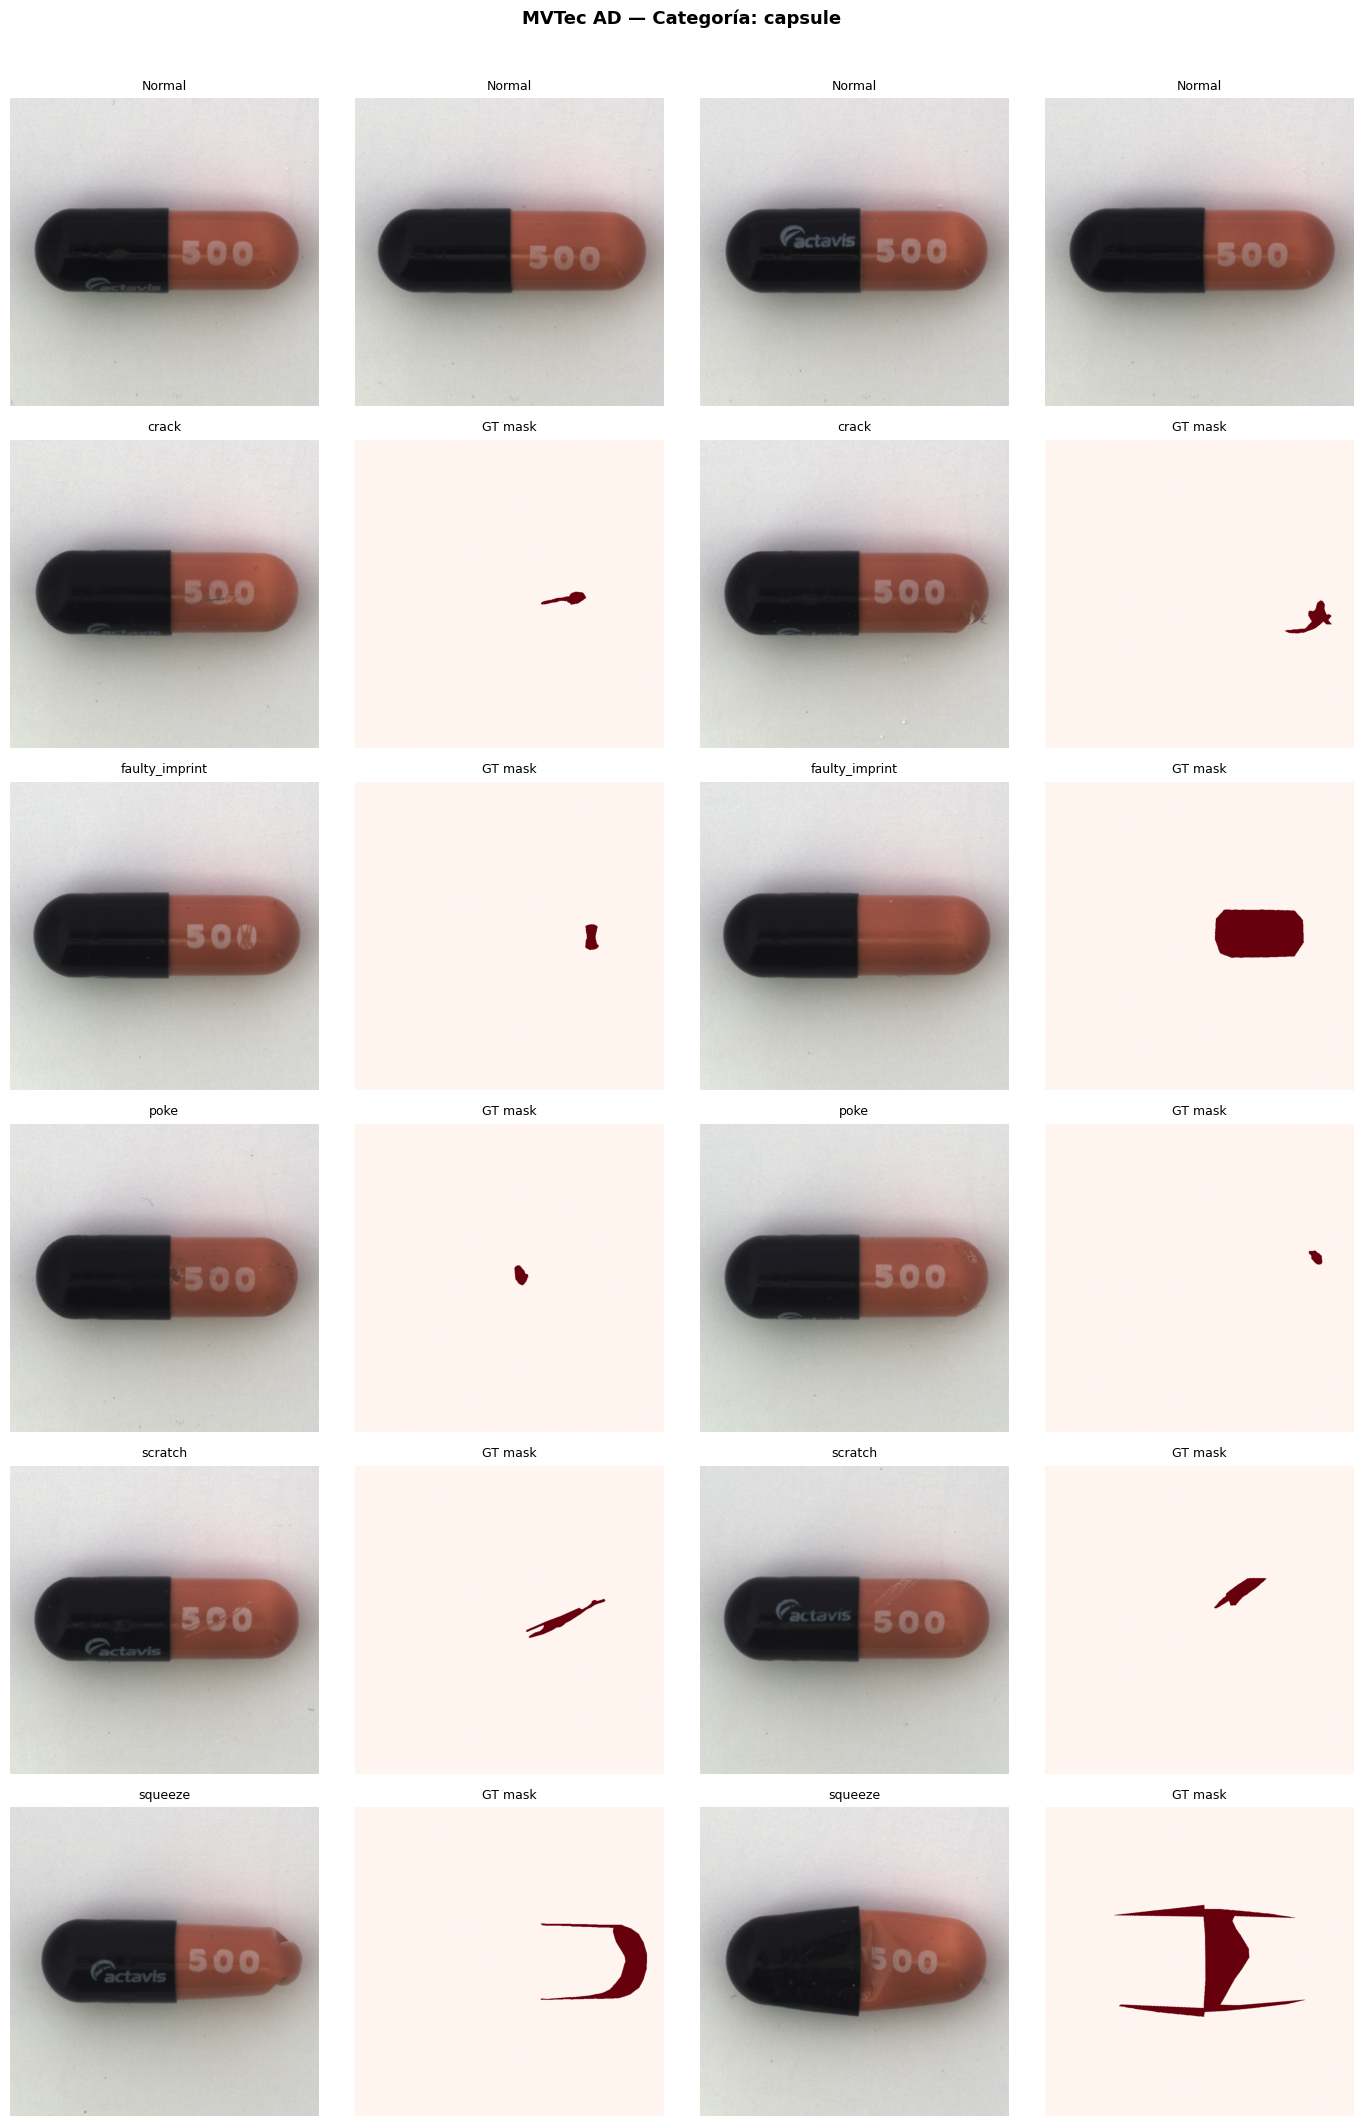

Figura guardada en /content/dataset_samples.png


In [14]:
import matplotlib.pyplot as plt
import matplotlib.patches as mpatches
from PIL import Image
import random, os

def show_dataset_samples(mvtec_root, category, n_normal=4, n_defect_per_type=2, seed=42):
    random.seed(seed)
    cat_root = mvtec_root / category

    # Imágenes normales (train/good)
    normal_dir = cat_root / 'train' / 'good'
    normal_imgs = sorted(normal_dir.glob('*.png'))
    selected_normal = random.sample(normal_imgs, min(n_normal, len(normal_imgs)))

    # Tipos de defecto (test/<tipo> excepto 'good')
    test_root = cat_root / 'test'
    defect_types = [d for d in sorted(os.listdir(test_root)) if d != 'good']

    fig_rows = 1 + len(defect_types)
    fig, axes = plt.subplots(fig_rows, max(n_normal, n_defect_per_type + 1),
                             figsize=(14, 3.5 * fig_rows))
    if fig_rows == 1:
        axes = [axes]

    # Fila 0: normales
    for col, p in enumerate(selected_normal):
        axes[0][col].imshow(Image.open(p))
        axes[0][col].set_title('Normal', fontsize=9)
        axes[0][col].axis('off')
    for col in range(len(selected_normal), axes[0].shape[0] if hasattr(axes[0], '__len__') else n_normal):
        try: axes[0][col].axis('off')
        except: pass

    # Filas siguientes: cada tipo de defecto + su máscara GT
    for row, dtype in enumerate(defect_types, start=1):
        defect_imgs = sorted((test_root / dtype).glob('*.png'))
        selected_defect = random.sample(defect_imgs, min(n_defect_per_type, len(defect_imgs)))
        col = 0
        for p in selected_defect:
            axes[row][col].imshow(Image.open(p))
            axes[row][col].set_title(f'{dtype}', fontsize=9)
            axes[row][col].axis('off')
            col += 1
            # Máscara GT correspondiente
            gt_path = cat_root / 'ground_truth' / dtype / (p.stem + '_mask.png')
            if gt_path.exists():
                axes[row][col].imshow(Image.open(gt_path), cmap='Reds', vmin=0, vmax=255)
                axes[row][col].set_title('GT mask', fontsize=9)
                axes[row][col].axis('off')
                col += 1
        for c in range(col, len(axes[row]) if hasattr(axes[row], '__len__') else n_normal):
            try: axes[row][c].axis('off')
            except: pass

    plt.suptitle(f'MVTec AD — Categoría: {category}', fontsize=13, fontweight='bold', y=1.01)
    plt.tight_layout()
    plt.savefig('/content/dataset_samples.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Figura guardada en /content/dataset_samples.png')

show_dataset_samples(MVTEC_ROOT, CATEGORY)


## 3. Pipeline: SAM 1 → PatchCore

### Arquitectura propuesta

```
Imagen original (MVTec AD)
        │
        ▼
  ┌─────────────┐
  │    SAM 1    │  ← SamAutomaticMaskGenerator (zero-shot, sin fine-tuning)
  │  ViT-H      │     Genera todas las máscaras candidatas
  │             │     Selecciona la de mayor área → bounding box
  └─────┬───────┘
        │  ROI recortada
        ▼
  ┌─────────────────────┐
  │     PatchCore        │  ← Backbone: WideResNet-50-2 (ImageNet)
  │  (Memory bank de     │     Capas: layer2 + layer3
  │   parches normales)  │     Coreset: 10 % approx greedy
  └─────────────────────┘
        │
        ▼
  Anomaly score (imagen) + Heatmap (píxel)
```

El **Baseline** omite el bloque SAM y pasa la imagen completa directamente a PatchCore.


In [16]:
# Descarga del checkpoint SAM 1 — ViT-H (mayor precisión, usado en el paper original)
SAM1_CKPT = DATA_ROOT / 'sam_vit_h_4b8939.pth'

if not SAM1_CKPT.exists():
    !wget -q -O {SAM1_CKPT} \
        https://dl.fbaipublicfiles.com/segment_anything/sam_vit_h_4b8939.pth
    print('Checkpoint descargado:', SAM1_CKPT)
else:
    print('Checkpoint ya existe:', SAM1_CKPT)


Checkpoint descargado: /content/data/sam_vit_h_4b8939.pth


In [17]:
import numpy as np
from PIL import Image
from tqdm import tqdm

from segment_anything import SamAutomaticMaskGenerator, sam_model_registry

device = 'cuda' if __import__('torch').cuda.is_available() else 'cpu'

sam = sam_model_registry['vit_h'](checkpoint=str(SAM1_CKPT))
sam.to(device)
mask_generator = SamAutomaticMaskGenerator(sam)
print(f'SAM 1 (vit_h) listo en {device}')


SAM 1 (vit_h) listo en cuda


## 4.0. Validación previa de SAM 1

Antes de construir el dataset ROI, se visualiza una muestra normal y una anómala con:
- máscara seleccionada por SAM,
- contorno/caja de segmentación,
- y la imagen recortada/mascarada.

Esto permite verificar si SAM está segmentando el objeto y no devolviendo la imagen completa.

Figura guardada en /content/sam_validation_good.png


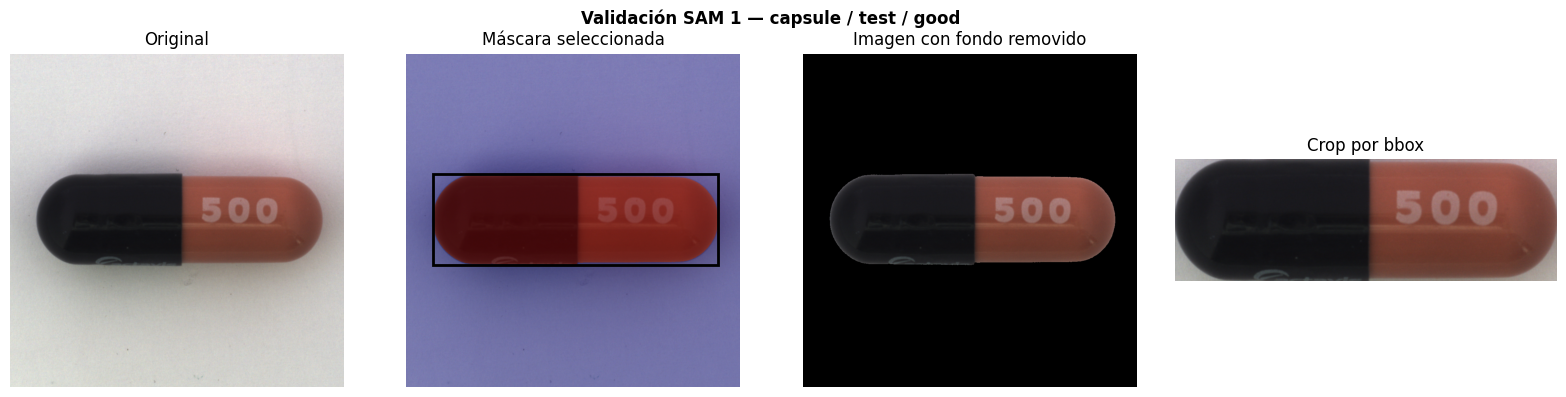

Figura guardada en /content/sam_validation_defect.png


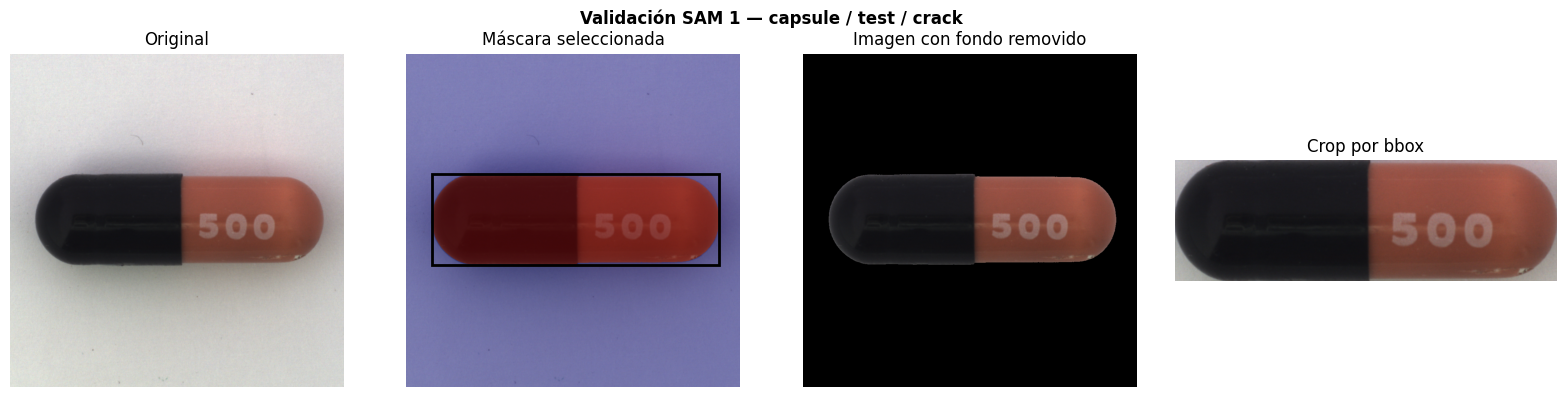

In [18]:
from pathlib import Path
from matplotlib.patches import Rectangle
import numpy as np
import matplotlib.pyplot as plt
from PIL import Image

def _apply_binary_mask(image: Image.Image, mask: np.ndarray, fill_value: int = 0) -> Image.Image:
    # Aplica una máscara binaria y deja el fondo en negro.
    arr = np.array(image).copy()
    if mask is None:
        return image.copy()
    mask = mask.astype(bool)
    arr[~mask] = fill_value
    return Image.fromarray(arr)

def _mask_bbox(mask: np.ndarray):
    ys, xs = np.where(mask)
    if len(xs) == 0 or len(ys) == 0:
        return None
    return int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max())

def _score_mask(mask_dict, image_size, min_area_ratio=0.03, max_area_ratio=0.95):
    w, h = image_size
    img_area = float(w * h)
    seg = mask_dict.get('segmentation', None)
    if seg is None:
        return None

    area = float(mask_dict.get('area', float(np.sum(seg))))
    ratio = area / img_area
    if ratio < min_area_ratio or ratio > max_area_ratio:
        return None

    bbox = _mask_bbox(seg)
    if bbox is None:
        return None

    x0, y0, x1, y1 = bbox
    bbox_area = max((x1 - x0 + 1) * (y1 - y0 + 1), 1)
    fill = area / bbox_area
    edge_touch = int(x0 <= 1) + int(y0 <= 1) + int(x1 >= w - 2) + int(y1 >= h - 2)

    score = (
        0.60 * float(mask_dict.get('predicted_iou', 0.0)) +
        0.40 * float(mask_dict.get('stability_score', 0.0)) +
        0.25 * fill -
        0.15 * edge_touch -
        abs(ratio - 0.35)
    )
    return score, bbox, seg, ratio, mask_dict

def select_sam_foreground_mask(masks, image_size, min_area_ratio=0.03, max_area_ratio=0.95):
    if not masks:
        return None, None, None

    scored = []
    fallback = []

    for m in masks:
        seg = m.get('segmentation', None)
        if seg is None:
            continue
        bbox = _mask_bbox(seg)
        if bbox is None:
            continue
        area = float(m.get('area', float(np.sum(seg))))
        ratio = area / float(image_size[0] * image_size[1])
        if ratio < min_area_ratio or ratio > max_area_ratio:
            continue
        item = _score_mask(m, image_size, min_area_ratio=min_area_ratio, max_area_ratio=max_area_ratio)
        if item is not None:
            scored.append(item)
        else:
            fallback.append((area, bbox, seg, ratio, m))

    if scored:
        scored.sort(key=lambda t: t[0], reverse=True)
        _, bbox, seg, _, meta = scored[0]
        return bbox, seg, meta

    if fallback:
        fallback.sort(key=lambda t: t[0], reverse=True)
        _, bbox, seg, _, meta = fallback[0]
        return bbox, seg, meta

    best = max(masks, key=lambda m: float(m.get('area', 0)))
    seg = best.get('segmentation', None)
    bbox = _mask_bbox(seg) if seg is not None else None
    return bbox, seg, best

def preview_sam_segmentation(image_path, title=None, save_path=None):
    image = Image.open(image_path).convert('RGB')
    masks = mask_generator.generate(np.array(image))
    bbox, seg, meta = select_sam_foreground_mask(masks, image.size)

    fig, axes = plt.subplots(1, 4, figsize=(16, 4))
    axes[0].imshow(image)
    axes[0].set_title('Original')
    axes[0].axis('off')

    axes[1].imshow(image)
    if seg is not None:
        axes[1].imshow(seg, cmap='jet', alpha=0.45)
    if bbox is not None:
        x0, y0, x1, y1 = bbox
        axes[1].add_patch(Rectangle((x0, y0), x1 - x0 + 1, y1 - y0 + 1,
                                    fill=False, linewidth=2))
    axes[1].set_title('Máscara seleccionada')
    axes[1].axis('off')

    if seg is not None:
        masked = _apply_binary_mask(image, seg)
        axes[2].imshow(masked)
        axes[2].set_title('Imagen con fondo removido')
    else:
        axes[2].imshow(image)
        axes[2].set_title('Sin máscara útil')
    axes[2].axis('off')

    if bbox is not None:
        crop = image.crop((bbox[0], bbox[1], bbox[2] + 1, bbox[3] + 1))
        axes[3].imshow(crop)
        axes[3].set_title('Crop por bbox')
    else:
        axes[3].imshow(image)
        axes[3].set_title('Fallback completo')
    axes[3].axis('off')

    if title:
        plt.suptitle(title, fontsize=12, fontweight='bold')
    plt.tight_layout()

    if save_path:
        plt.savefig(save_path, dpi=140, bbox_inches='tight')
        print('Figura guardada en', save_path)

    plt.show()

good_sample = sorted((MVTEC_ROOT / CATEGORY / 'test' / 'good').glob('*.png'))[:1]
if good_sample:
    preview_sam_segmentation(
        good_sample[0],
        title=f'Validación SAM 1 — {CATEGORY} / test / good',
        save_path='/content/sam_validation_good.png'
    )

defect_dirs = [d for d in sorted((MVTEC_ROOT / CATEGORY / 'test').iterdir()) if d.is_dir() and d.name != 'good']
if defect_dirs:
    first_defect = sorted(defect_dirs[0].glob('*.png'))[:1]
    if first_defect:
        preview_sam_segmentation(
            first_defect[0],
            title=f'Validación SAM 1 — {CATEGORY} / test / {defect_dirs[0].name}',
            save_path='/content/sam_validation_defect.png'
        )

## 4. Generación de ROI con SAM 1

In [20]:
import os, shutil, cv2

ROI_ROOT          = DATA_ROOT / 'mvtec_sam_roi'
ROI_CATEGORY_ROOT = ROI_ROOT / CATEGORY

# ──────────────────────────────────────────────
# Utilidades
# ──────────────────────────────────────────────
def _largest_mask_bbox(masks, min_area=100):
    if not masks:
        return None
    masks = sorted(masks, key=lambda m: m['area'], reverse=True)
    for m in masks:
        if m['area'] >= min_area:
            ys, xs = np.where(m['segmentation'])
            if len(xs) == 0 or len(ys) == 0:
                continue
            return (int(xs.min()), int(ys.min()), int(xs.max()), int(ys.max()))
    return None

def _safe_crop(image, bbox):
    x0, y0, x1, y1 = bbox
    return image.crop((x0, y0, x1 + 1, y1 + 1))

def _full_bbox(image):
    w, h = image.size
    return (0, 0, w - 1, h - 1)

def _ensure_mask(path, size):
    if path.exists():
        return
    Image.new('L', size, color=0).save(path)

def _mask_to_image_name(mask_name):
    stem = mask_name.rsplit('.', 1)[0]
    if stem.endswith('_mask'):
        stem = stem[:-5]
    return f"{stem}.png"

# ──────────────────────────────────────────────
# Construcción del dataset ROI
# ──────────────────────────────────────────────
def build_roi_dataset():
    src_root = MVTEC_ROOT / CATEGORY
    dst_root = ROI_CATEGORY_ROOT
    bbox_map = {}

    if dst_root.exists():
        shutil.rmtree(dst_root)
    dst_root.mkdir(parents=True, exist_ok=True)

    for split in ['train', 'test']:
        split_root = src_root / split
        bbox_map[split] = {}
        for defect_type in sorted(os.listdir(split_root)):
            defect_root = split_root / defect_type
            if not defect_root.is_dir():
                continue
            dst_defect_root = dst_root / split / defect_type
            dst_defect_root.mkdir(parents=True, exist_ok=True)
            bbox_map[split][defect_type] = {}

            for img_name in tqdm(sorted(os.listdir(defect_root)),
                                 desc=f'SAM {split}/{defect_type}'):
                if not img_name.lower().endswith(('.png', '.jpg', '.jpeg')):
                    continue
                img_path   = defect_root / img_name
                image      = Image.open(img_path).convert('RGB')
                masks = mask_generator.generate(np.array(image))
                try:
                    bbox, seg, meta = select_sam_foreground_mask(masks, image.size)
                except Exception:
                    bbox = _largest_mask_bbox(masks) or _full_bbox(image)
                    seg = None

                bbox_map[split][defect_type][img_name] = bbox

                if seg is not None:
                    image_np = np.array(image)
                    foreground = image_np.copy()
                    foreground[~seg] = 0
                    crop_img = _safe_crop(Image.fromarray(foreground), bbox)
                else:
                    crop_img = _safe_crop(image, bbox)

                crop_img.save(dst_defect_root / img_name)

    # Ground truth (test únicamente)
    gt_root = src_root / 'ground_truth'
    if gt_root.exists():
        for defect_type in sorted(os.listdir(gt_root)):
            defect_root     = gt_root / defect_type
            if not defect_root.is_dir():
                continue
            dst_defect_root = dst_root / 'ground_truth' / defect_type
            dst_defect_root.mkdir(parents=True, exist_ok=True)
            for mask_name in tqdm(sorted(os.listdir(defect_root)),
                                  desc=f'GT {defect_type}'):
                if not mask_name.lower().endswith('.png'):
                    continue
                img_name  = _mask_to_image_name(mask_name)
                img_path  = src_root / 'test' / defect_type / img_name
                if not img_path.exists():
                    Image.open(gt_root / defect_type / mask_name).save(
                        dst_defect_root / mask_name)
                    continue
                image = Image.open(img_path).convert('RGB')
                bbox  = bbox_map.get('test', {}).get(defect_type, {}).get(
                    img_name, _full_bbox(image))
                gt_mask = Image.open(gt_root / defect_type / mask_name)
                _safe_crop(gt_mask, bbox).save(dst_defect_root / mask_name)

    # Asegura una máscara por imagen anómala
    test_root   = dst_root / 'test'
    gt_root_out = dst_root / 'ground_truth'
    for defect_type in sorted(os.listdir(test_root)):
        if defect_type == 'good':
            continue
        gt_defect = gt_root_out / defect_type
        gt_defect.mkdir(parents=True, exist_ok=True)
        for img_path in sorted((test_root / defect_type).iterdir()):
            if img_path.suffix.lower() != '.png':
                continue
            mask_path = gt_defect / (img_path.stem + '_mask.png')
            _ensure_mask(mask_path, Image.open(img_path).size)

    print('ROI dataset listo:', dst_root)

build_roi_dataset()


GT squeeze: 100%|██████████| 20/20 [00:00<00:00, 21.46it/s]

ROI dataset listo: /content/data/mvtec_sam_roi/capsule


In [21]:
def check_roi_consistency():
    test_root = ROI_ROOT / CATEGORY / 'test'
    gt_root   = ROI_ROOT / CATEGORY / 'ground_truth'
    print(f'\n--- Consistencia ROI ({CATEGORY}) ---')
    for defect_type in sorted(os.listdir(test_root)):
        if defect_type == 'good':
            continue
        tc = len([p for p in (test_root / defect_type).iterdir()
                  if p.suffix.lower() == '.png'])
        gc = len([p for p in (gt_root / defect_type).iterdir()
                  if p.suffix.lower() == '.png']) if (gt_root / defect_type).exists() else 0
        status = 'ALINEADO' if tc == gc else ' DESALINEADO'
        print(f'  {status} {defect_type}: test={tc} gt={gc}')

check_roi_consistency()


--- Consistencia ROI (capsule) ---
  ALINEADO crack: test=23 gt=23
  ALINEADO faulty_imprint: test=22 gt=22
  ALINEADO poke: test=21 gt=21
  ALINEADO scratch: test=23 gt=23
  ALINEADO squeeze: test=20 gt=20


## 4.1. Visualización: imagen original vs ROI segmentada por SAM 1

Se comparan ejemplos del conjunto de test para mostrar el recorte generado por SAM.

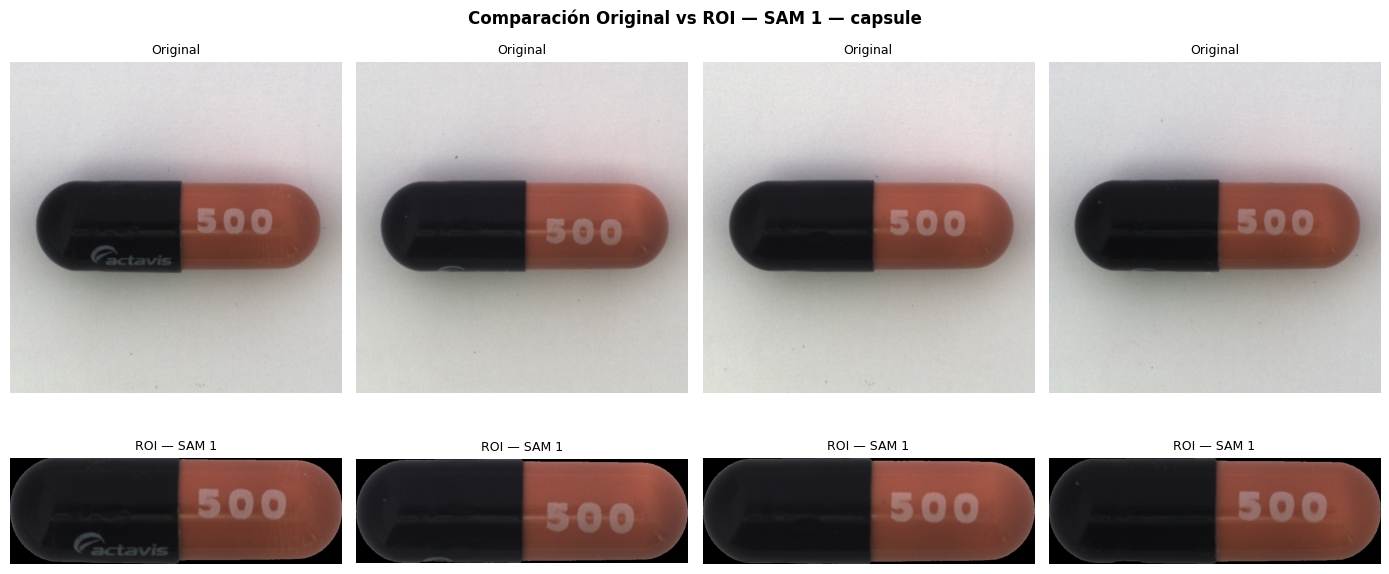

Figura guardada en /content/sam_roi_comparison.png


In [22]:
import numpy as np
import matplotlib.pyplot as plt
import random

def show_sam_crops(mvtec_root, roi_root, category, n=4, seed=0):
    random.seed(seed)
    test_good = mvtec_root / category / 'test' / 'good'
    roi_good  = roi_root   / category / 'test' / 'good'
    all_samples = sorted(list(test_good.glob('*.png')))
    samples = random.sample(all_samples, min(n, len(all_samples)))

    fig, axes = plt.subplots(2, len(samples), figsize=(3.5 * len(samples), 7))
    if len(samples) == 1:
        axes = np.array(axes).reshape(2, 1)

    for col, p in enumerate(samples):
        axes[0][col].imshow(Image.open(p))
        axes[0][col].set_title('Original', fontsize=9)
        axes[0][col].axis('off')

        roi_path = roi_good / p.name
        axes[1][col].imshow(Image.open(roi_path))
        axes[1][col].set_title('ROI — SAM 1', fontsize=9)
        axes[1][col].axis('off')

    plt.suptitle(f'Comparación Original vs ROI — SAM 1 — {category}',
                 fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/sam_roi_comparison.png', dpi=120, bbox_inches='tight')
    plt.show()
    print('Figura guardada en /content/sam_roi_comparison.png')

show_sam_crops(MVTEC_ROOT, ROI_ROOT, CATEGORY)

In [78]:
# ===== PARCHAR run_patchcore.py ANTES de ejecutar PatchCore =====
# Fix 1: transform_std/transform_mean -> ImageNet stats
# Fix 2: Insertar guardado de datos crudos (anomaly maps + scores)
from pathlib import Path

patchcore_script = Path("patchcore-inspection/bin/run_patchcore.py")
content = patchcore_script.read_text()

# --- Fix 1: transform_std/transform_mean ---
old_new_pairs = [
    ("dataloaders[\"testing\"].dataset.transform_std",  "[0.229, 0.224, 0.225]"),
    ("dataloaders[\"testing\"].dataset.transform_mean", "[0.485, 0.456, 0.406]"),
]
for s_old, s_new in old_new_pairs:
    if s_old in content:
        content = content.replace(s_old, s_new)
        print(f"  Reemplazado: {s_old[:60]}...")

# --- Fix 2: Guardar datos crudos (anomaly maps + scores) ---
old2 = "patchcore.utils.plot_segmentation_images("
new2 = (
    "# === GUARDAR DATOS CRUDOS PARA NOTEBOOK ===\n"
    "                import pickle as _pickle\n"
    "                _dd = os.path.join(run_save_path, \"anomaly_data\")\n"
    "                os.makedirs(_dd, exist_ok=True)\n"
    "                with open(os.path.join(_dd, \"anomaly_data.pkl\"), \"wb\") as _f:\n"
    "                    _pickle.dump({\n"
    "                        \"segmentations\": segmentations,\n"
    "                        \"scores\": scores,\n"
    "                        \"labels\": anomaly_labels,\n"
    "                        \"image_paths\": image_paths,\n"
    "                    }, _f)\n"
    "                patchcore.utils.plot_segmentation_images(\n"
)
if old2 in content:
    content = content.replace(old2, new2)
    print("  + Guardado de datos crudos (anomaly_data.pkl) insertado")
else:
    print("  ! No se encontro plot_segmentation_images en run_patchcore.py")

patchcore_script.write_text(content)
print("run_patchcore.py parcheado: ImageNet stats + guardado de datos crudos")

# --- Monkey-patch MVTecDataset (seguridad extra) ---
try:
    import numpy as np
    from patchcore.datasets.mvtec import MVTecDataset
    MVTecDataset.transform_std  = [0.229, 0.224, 0.225]
    MVTecDataset.transform_mean = [0.485, 0.456, 0.406]
    print("MVTecDataset monkey-patched (transform_std/mean)")
except Exception as e:
    print(f"MVTecDataset patch no necesario: {e}")


  + Guardado de datos crudos (anomaly_data.pkl) insertado
run_patchcore.py parcheado: ImageNet stats + guardado de datos crudos
MVTecDataset patch no necesario: No module named 'patchcore'


## 5. PatchCore — Baseline (imagen completa)

PatchCore se entrena y evalúa directamente sobre las imágenes originales de MVTec AD.  
**Backbone**: WideResNet-50-2 (ImageNet) — capas `layer2` + `layer3`.


In [79]:
BASELINE_OUT = DATA_ROOT / 'results_baseline'
BASELINE_OUT.mkdir(parents=True, exist_ok=True)

cmd = ' '.join([
    'env', 'PYTHONPATH=patchcore-inspection/src', 'python',
    'patchcore-inspection/bin/run_patchcore.py',
    '--gpu', '0', '--seed', '0', '--save_patchcore_model',
    '--log_group', 'IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0',
    str(BASELINE_OUT),
    'patch_core',
    '-b', 'wideresnet50', '-le', 'layer2', '-le', 'layer3',
    '--pretrain_embed_dimension', '1024', '--target_embed_dimension', '1024',
    '--anomaly_scorer_num_nn', '1', '--patchsize', '3',
    'sampler', '-p', '0.1', 'approx_greedy_coreset',
    'dataset', '--resize', '256', '--imagesize', '224',
    '-d', CATEGORY, 'mvtec', str(MVTEC_ROOT)
])

print('Ejecutando baseline...')
!{cmd}


Ejecutando baseline...
INFO:__main__:Command line arguments: patchcore-inspection/bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --save_segmentation_images --log_group IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0 /content/data/results_baseline patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d capsule mvtec /content/data
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker_number_rationality()
INFO:__m

## 6. PatchCore — SAM 1 + ROI

In [74]:
ROI_OUT = DATA_ROOT / 'results_sam_roi'
ROI_OUT.mkdir(parents=True, exist_ok=True)

cmd = ' '.join([
    'env', 'PYTHONPATH=patchcore-inspection/src', 'python',
    'patchcore-inspection/bin/run_patchcore.py',
    '--gpu', '0', '--seed', '0', '--save_patchcore_model',
    '--log_group', 'IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_SAM1ROI',
    str(ROI_OUT),
    'patch_core',
    '-b', 'wideresnet50', '-le', 'layer2', '-le', 'layer3',
    '--pretrain_embed_dimension', '1024', '--target_embed_dimension', '1024',
    '--anomaly_scorer_num_nn', '1', '--patchsize', '3',
    'sampler', '-p', '0.1', 'approx_greedy_coreset',
    'dataset', '--resize', '256', '--imagesize', '224',
    '-d', CATEGORY, 'mvtec', str(ROI_ROOT)
])

print('Ejecutando SAM 1 + PatchCore...')
!{cmd}


Ejecutando SAM 1 + PatchCore...
INFO:__main__:Command line arguments: patchcore-inspection/bin/run_patchcore.py --gpu 0 --seed 0 --save_patchcore_model --save_segmentation_images --log_group IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_SAM1ROI /content/data/results_sam_roi patch_core -b wideresnet50 -le layer2 -le layer3 --pretrain_embed_dimension 1024 --target_embed_dimension 1024 --anomaly_scorer_num_nn 1 --patchsize 3 sampler -p 0.1 approx_greedy_coreset dataset --resize 256 --imagesize 224 -d capsule mvtec /content/data/mvtec_sam_roi
/usr/local/lib/python3.12/dist-packages/torch/utils/data/dataloader.py:424: UserWarning: This DataLoader will create 8 worker processes in total. Our suggested max number of worker in current system is 2, which is smaller than what this DataLoader is going to create. Please be aware that excessive worker creation might get DataLoader running slow or even freeze, lower the worker number to avoid potential slowness/freeze if necessary.
  self.check_worker

In [55]:
from pathlib import Path
import shutil

def _copy_results_csv(out_root: Path) -> Path | None:
    out_root = Path(out_root)
    direct = out_root / "results.csv"
    if direct.exists():
        return direct
    candidates = list(out_root.rglob("results.csv"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    src = candidates[0]
    shutil.copy2(src, direct)
    return direct

for name, out_dir in [("baseline", BASELINE_OUT), ("sam_roi", ROI_OUT)]:
    copied = _copy_results_csv(out_dir)
    if copied:
        print(f"results.csv ({name}) listo en: {copied}")
    else:
        print(f"No se encontro results.csv para {name}")

results.csv (baseline) listo en: /content/data/results_baseline/results.csv
results.csv (sam_roi) listo en: /content/data/results_sam_roi/results.csv


In [56]:
import pandas as pd

def load_results(results_root):
    csv_path = Path(results_root) / 'results.csv'
    if not csv_path.exists():
        print('No se encontró:', csv_path)
        return None
    df = pd.read_csv(csv_path)
    if 'dataset' not in df.columns and 'Row Names' in df.columns:
        # Normaliza el nombre de la clase para que coincida con CATEGORY.
        df['dataset'] = (
            df['Row Names']
            .astype(str)
            .str.replace('mvtec_', '', regex=False)
            .str.replace('mvtec-', '', regex=False)
        )
    return df

baseline_df = load_results(BASELINE_OUT)
roi_df      = load_results(ROI_OUT)

# cols = ['dataset', 'instance_auroc', 'full_pixel_auroc', 'anomaly_pixel_auroc']

# print('\n=== Baseline (imagen completa) ===')
# if baseline_df is not None:
#     row = baseline_df[baseline_df['dataset'] == CATEGORY]
#     print(row[cols].to_string(index=False))

# print('\n=== SAM 1 + PatchCore (ROI) ===')
# if roi_df is not None:
#     row = roi_df[roi_df['dataset'] == CATEGORY]
#     print(row[cols].to_string(index=False))


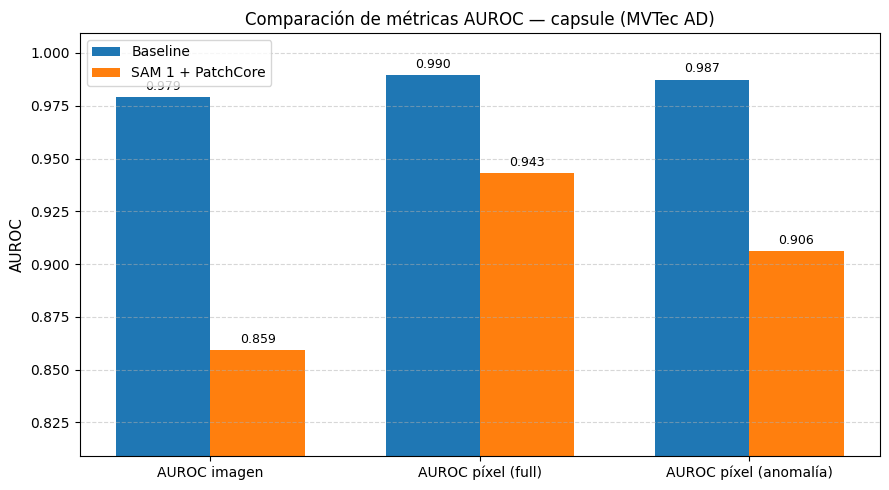

Figura guardada en /content/results_table.png


In [57]:
import matplotlib.pyplot as plt
import numpy as np

def plot_comparison_table(baseline_df, roi_df, category, save_path='/content/results_table.png'):
    metrics  = ['AUROC imagen', 'AUROC píxel (full)', 'AUROC píxel (anomalía)']
    col_keys = ['instance_auroc', 'full_pixel_auroc', 'anomaly_pixel_auroc']

    def _get(df):
        if df is None:
            return [np.nan] * 3
        row = df[df['dataset'] == category]
        if row.empty:
            return [np.nan] * 3
        vals = []
        for k in col_keys:
            vals.append(float(row[k].values[0]) if k in row.columns else np.nan)
        return vals

    baseline_vals = _get(baseline_df)
    roi_vals      = _get(roi_df)

    x = np.arange(len(metrics))
    w = 0.35
    fig, ax = plt.subplots(figsize=(9, 5))
    bars1 = ax.bar(x - w / 2, np.nan_to_num(baseline_vals, nan=0.0), w, label='Baseline')
    bars2 = ax.bar(x + w / 2, np.nan_to_num(roi_vals, nan=0.0), w, label='SAM 1 + PatchCore')

    for bar, val in list(zip(bars1, baseline_vals)) + list(zip(bars2, roi_vals)):
        if np.isnan(val):
            continue
        ax.text(bar.get_x() + bar.get_width() / 2, val + 0.002,
                f'{val:.3f}', ha='center', va='bottom', fontsize=9)

    all_vals = [v for v in (baseline_vals + roi_vals) if not np.isnan(v)]
    if all_vals:
        ymin = max(0.0, min(all_vals) - 0.05)
        ymax = min(1.01, max(all_vals) + 0.02)
        if ymax - ymin < 0.05:
            ymax = min(1.01, ymin + 0.05)
        ax.set_ylim(ymin, ymax)
    else:
        ax.set_ylim(0.0, 1.0)
    ax.set_ylabel('AUROC', fontsize=11)
    ax.set_xticks(x)
    ax.set_xticklabels(metrics, fontsize=10)
    ax.set_title(f'Comparación de métricas AUROC — {category} (MVTec AD)', fontsize=12)
    ax.legend(fontsize=10)
    ax.yaxis.grid(True, linestyle='--', alpha=0.5)
    plt.tight_layout()
    plt.savefig(save_path, dpi=150, bbox_inches='tight')
    plt.show()
    print('Figura guardada en', save_path)

plot_comparison_table(baseline_df, roi_df, CATEGORY)

## 8. Resultados visuales: mapas de calor de anomalías

Se muestran, para imágenes con defectos de la clase *capsule*, la imagen original,  
la ROI recortada por SAM 1 y el mapa de calor generado por PatchCore.  
Esto permite evaluar cualitativamente si la segmentación mejora la localización.


In [ ]:
# ===== MAPAS DE CALOR REALES desde datos crudos de PatchCore =====
from pathlib import Path
import matplotlib.pyplot as plt
import matplotlib.cm as cm
import numpy as np
from PIL import Image, ImageOps
import os, random, pickle

def _load_anomaly_data(results_dir):
    """Carga el .pkl guardado por run_patchcore.py con datos crudos."""
    results_dir = Path(results_dir)
    candidates = list(results_dir.rglob("anomaly_data.pkl"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    with open(candidates[0], "rb") as f:
        return pickle.load(f)

def _find_matching_segmentation(data, image_stem):
    """Busca la segmentation cuyo image_path contiene el stem dado."""
    for i, img_path in enumerate(data["image_paths"]):
        if image_stem in str(img_path):
            return data["segmentations"][i], data["scores"][i]
    return None, None

def show_anomaly_heatmaps(mvtec_root, roi_root, baseline_out, roi_out,
                          category, defect_type=None, n=3, seed=1):
    """Muestra heatmaps reales de anomalia generados desde los datos crudos."""
    random.seed(seed)
    test_root = mvtec_root / category / "test"
    defect_types = (
        [defect_type] if defect_type
        else [d for d in sorted(os.listdir(test_root)) if d != "good"]
    )

    baseline_data = _load_anomaly_data(baseline_out)
    roi_data = _load_anomaly_data(roi_out)

    for dtype in defect_types[:3]:
        imgs = sorted((test_root / dtype).glob("*.png"))
        if not imgs:
            continue
        selected = random.sample(imgs, min(n, len(imgs)))
        ncols = 5
        fig, axes = plt.subplots(len(selected), ncols,
                                 figsize=(ncols * 3.2, len(selected) * 3.2))
        if len(selected) == 1:
            axes = [axes]

        for row, p in enumerate(selected):
            orig_img = Image.open(p).convert("RGB")
            axes[row][0].imshow(orig_img)
            axes[row][0].set_title("Original", fontsize=8)
            axes[row][0].axis("off")

            roi_img_path = roi_root / category / "test" / dtype / p.name
            roi_img = None
            if roi_img_path.exists():
                roi_img = Image.open(roi_img_path).convert("RGB")
                axes[row][1].imshow(roi_img)
            else:
                axes[row][1].text(0.5, 0.5, "N/D", ha="center", va="center")
            axes[row][1].set_title("ROI (SAM 1)", fontsize=8)
            axes[row][1].axis("off")

            seg_b, score_b = None, None
            if baseline_data:
                seg_b, score_b = _find_matching_segmentation(baseline_data, p.stem)
            if seg_b is not None:
                seg_resized = np.array(Image.fromarray(seg_b).resize(
                    orig_img.size, Image.NEAREST))
                axes[row][2].imshow(orig_img, cmap="gray", alpha=0.4)
                im = axes[row][2].imshow(seg_resized, cmap="jet", alpha=0.6, vmin=0, vmax=seg_b.max())
                plt.colorbar(im, ax=axes[row][2], fraction=0.046, pad=0.04)
                title_b = "Baseline"
                if score_b is not None:
                    title_b = "Baseline (score=" + str(round(score_b, 3)) + ")"
                axes[row][2].set_title(title_b, fontsize=8)
            else:
                axes[row][2].text(0.5, 0.5, "N/D", ha="center", va="center")
                axes[row][2].set_title("Baseline", fontsize=8)
            axes[row][2].axis("off")

            seg_r, score_r = None, None
            if roi_data:
                seg_r, score_r = _find_matching_segmentation(roi_data, p.stem)
            if seg_r is not None:
                ref_img = roi_img if roi_img is not None else orig_img
                seg_resized_r = np.array(Image.fromarray(seg_r).resize(
                    ref_img.size, Image.NEAREST))
                axes[row][3].imshow(ref_img, cmap="gray", alpha=0.4)
                im2 = axes[row][3].imshow(seg_resized_r, cmap="jet", alpha=0.6, vmin=0, vmax=seg_r.max())
                plt.colorbar(im2, ax=axes[row][3], fraction=0.046, pad=0.04)
                title_r = "SAM+PatchCore"
                if score_r is not None:
                    title_r = "SAM+PC (score=" + str(round(score_r, 3)) + ")"
                axes[row][3].set_title(title_r, fontsize=8)
            else:
                axes[row][3].text(0.5, 0.5, "N/D", ha="center", va="center")
                axes[row][3].set_title("SAM+PatchCore", fontsize=8)
            axes[row][3].axis("off")

            gt_path = mvtec_root / category / "ground_truth" / dtype / (p.stem + "_mask.png")
            if gt_path.exists():
                gt = Image.open(gt_path).convert("L")
                gt_arr = np.array(gt).astype(float)
                axes[row][4].imshow(gt_arr, cmap="Reds", vmin=0, vmax=255)
            else:
                axes[row][4].text(0.5, 0.5, "N/D", ha="center", va="center")
            axes[row][4].set_title("Ground Truth", fontsize=8)
            axes[row][4].axis("off")

        plt.suptitle("Mapas de calor -- " + category + " / " + dtype, fontsize=11, fontweight="bold")
        plt.tight_layout()
        save_path = "/content/heatmaps_" + category + "_" + dtype + ".png"
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        plt.show()
        print("Figura guardada en " + save_path)

show_anomaly_heatmaps(MVTEC_ROOT, ROI_ROOT, BASELINE_OUT, ROI_OUT, CATEGORY)


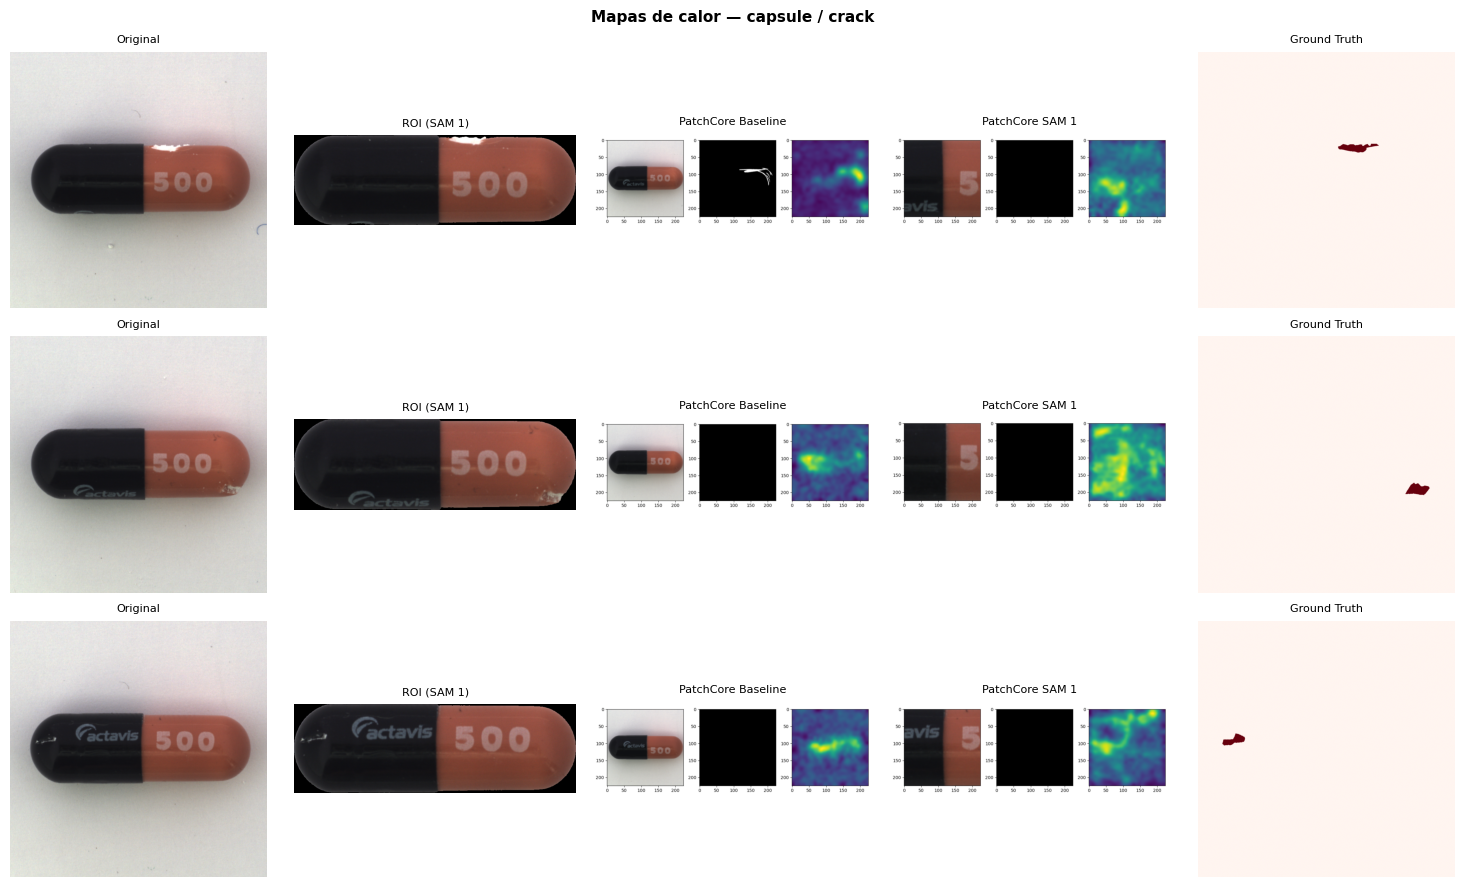

Figura guardada en /content/heatmaps_capsule_crack.png


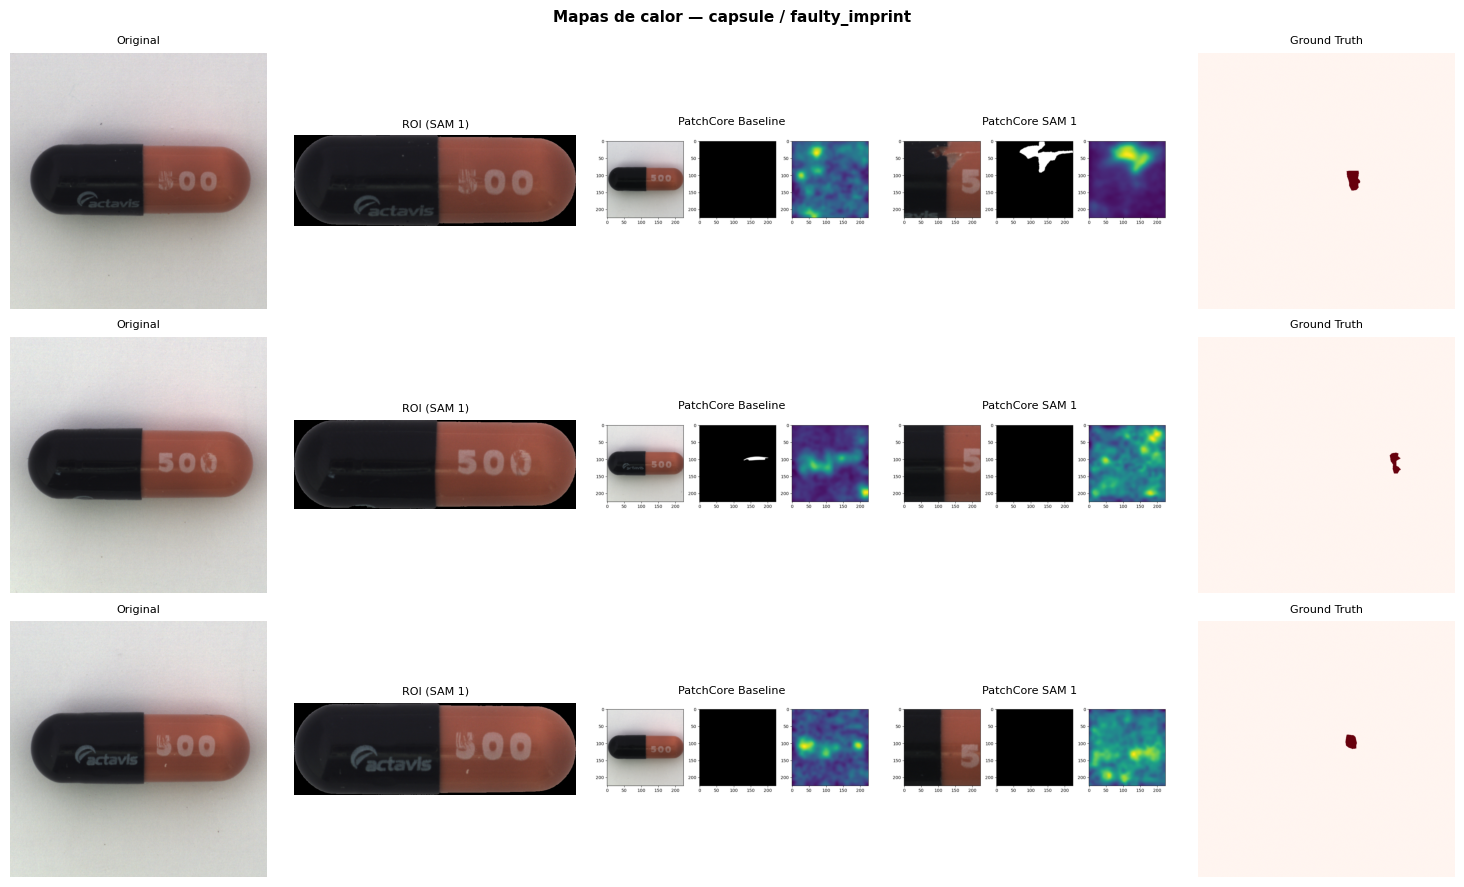

Figura guardada en /content/heatmaps_capsule_faulty_imprint.png


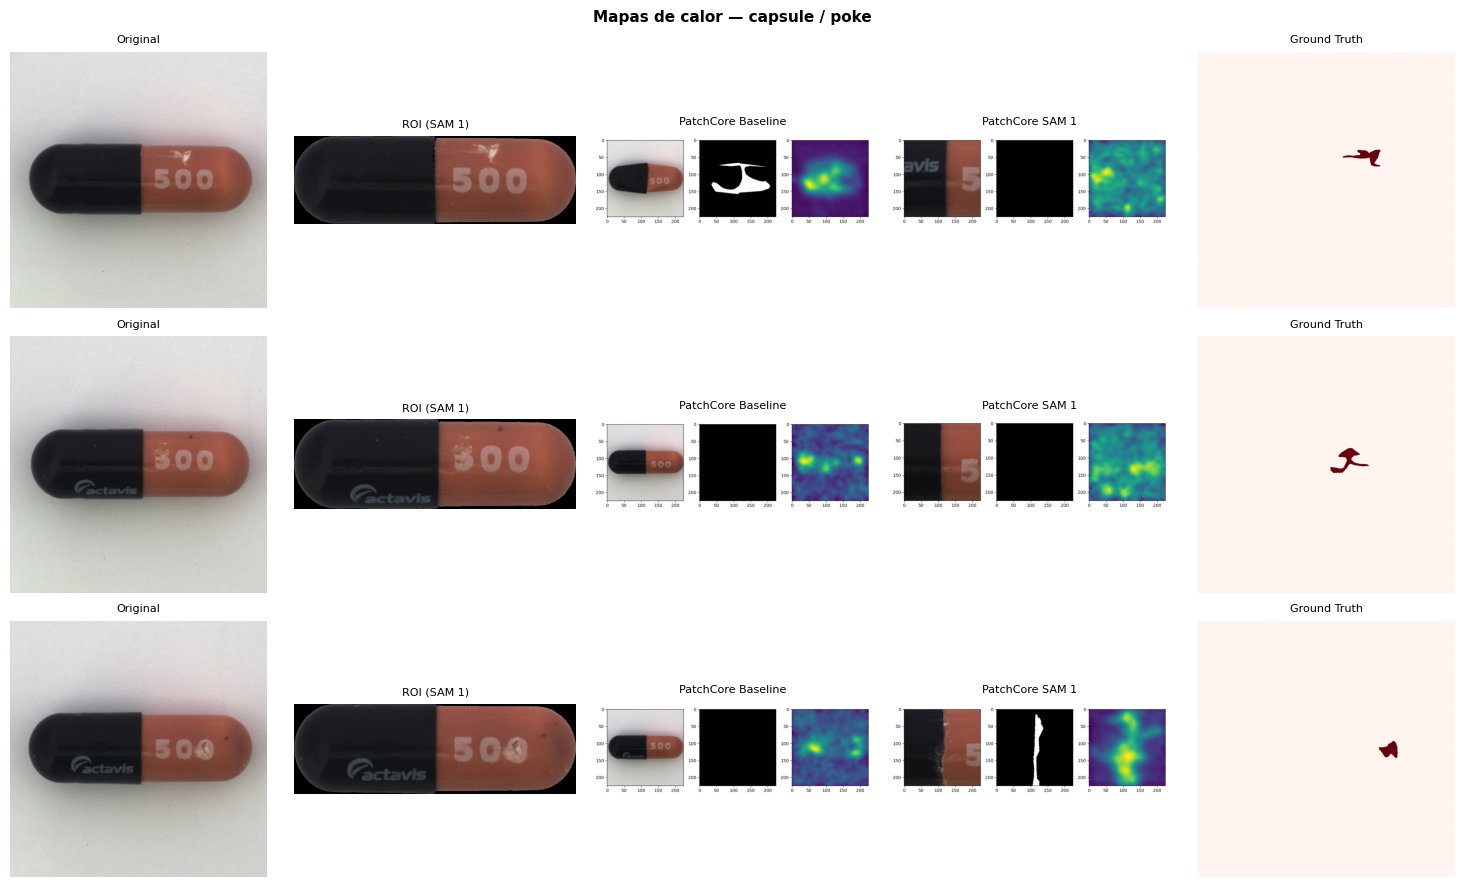

Figura guardada en /content/heatmaps_capsule_poke.png


In [62]:
# ===== MAPAS DE CALOR desde modelo PatchCore guardado =====
from pathlib import Path
import matplotlib.pyplot as plt
import numpy as np
import torch
from PIL import Image
import os, random

# Import PatchCore internals
from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN
from patchcore.datasets.mvtec import MVTecDataset, DatasetSplit

def _find_model_path(results_dir):
    """Busca el directorio donde PatchCore guardo el modelo."""
    results_dir = Path(results_dir)
    candidates = list(results_dir.rglob("patchcore_params.pkl"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    return candidates[0].parent

def _predict_with_model(model_path, data_root, category):
    """Carga modelo PatchCore y ejecuta prediccion sobre test set."""
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    pc = PatchCore(device)
    pc.load_from_path(
        load_path=str(model_path),
        device=device,
        nn_method=FaissNN(on_gpu=False, num_workers=4),
    )
    test_dataset = MVTecDataset(
        str(data_root),
        classname=category,
        resize=256,
        imagesize=224,
        split=DatasetSplit.TEST,
        seed=0,
    )
    test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )
    scores, segmentations, labels, masks = pc.predict(test_loader)
    image_paths = [x[2] for x in test_dataset.data_to_iterate]
    return image_paths, scores, segmentations, labels

def _find_seg_by_path(image_paths, segmentations, scores, stem):
    for i, p in enumerate(image_paths):
        if stem in str(p):
            return segmentations[i], scores[i]
    return None, None

def show_anomaly_heatmaps(mvtec_root, roi_root, baseline_out, roi_out,
                          category, defect_type=None, n=3, seed=1):
    """Heatmaps reales cargando modelo PatchCore guardado."""
    random.seed(seed)
    test_root = mvtec_root / category / "test"
    defect_types = (
        [defect_type] if defect_type
        else [d for d in sorted(os.listdir(test_root)) if d != "good"]
    )

    # Cargar modelos y predecir
    print("Cargando modelo Baseline...")
    b_path = _find_model_path(baseline_out)
    b_data = _predict_with_model(b_path, mvtec_root, category) if b_path else None

    print("Cargando modelo SAM+ROI...")
    r_path = _find_model_path(roi_out)
    r_data = _predict_with_model(r_path, roi_root, category) if r_path else None

    for dtype in defect_types[:3]:
        imgs = sorted((test_root / dtype).glob("*.png"))
        if not imgs:
            continue
        selected = random.sample(imgs, min(n, len(imgs)))
        ncols = 5
        fig, axes = plt.subplots(len(selected), ncols,
                                 figsize=(ncols * 3.2, len(selected) * 3.2))
        if len(selected) == 1:
            axes = [axes]

        for row, p in enumerate(selected):
            orig_img = Image.open(p).convert("RGB")
            axes[row][0].imshow(orig_img)
            axes[row][0].set_title("Original", fontsize=8)
            axes[row][0].axis("off")

            roi_img_path = roi_root / category / "test" / dtype / p.name
            roi_img = None
            if roi_img_path.exists():
                roi_img = Image.open(roi_img_path).convert("RGB")
                axes[row][1].imshow(roi_img)
            else:
                axes[row][1].text(0.5, 0.5, "N/D", ha="center", va="center")
            axes[row][1].set_title("ROI (SAM 1)", fontsize=8)
            axes[row][1].axis("off")

            # Baseline heatmap
            if b_data is not None:
                seg_b, score_b = _find_seg_by_path(b_data[0], b_data[1], b_data[2], p.stem)
                if seg_b is not None:
                    seg_resized = np.array(Image.fromarray(seg_b).resize(orig_img.size, Image.NEAREST))
                    axes[row][2].imshow(orig_img, cmap="gray", alpha=0.4)
                    im = axes[row][2].imshow(seg_resized, cmap="jet", alpha=0.6, vmin=0, vmax=seg_b.max())
                    plt.colorbar(im, ax=axes[row][2], fraction=0.046, pad=0.04)
                    axes[row][2].set_title("Baseline (score=" + str(round(score_b,3)) + ")" if score_b else "Baseline", fontsize=8)
                else:
                    axes[row][2].text(0.5, 0.5, "N/D", ha="center", va="center")
                    axes[row][2].set_title("Baseline", fontsize=8)
            else:
                axes[row][2].text(0.5, 0.5, "N/D", ha="center", va="center")
                axes[row][2].set_title("Baseline", fontsize=8)
            axes[row][2].axis("off")

            # SAM+ROI heatmap
            if r_data is not None:
                seg_r, score_r = _find_seg_by_path(r_data[0], r_data[1], r_data[2], p.stem)
                if seg_r is not None:
                    ref_img = roi_img if roi_img is not None else orig_img
                    seg_resized_r = np.array(Image.fromarray(seg_r).resize(ref_img.size, Image.NEAREST))
                    axes[row][3].imshow(ref_img, cmap="gray", alpha=0.4)
                    im2 = axes[row][3].imshow(seg_resized_r, cmap="jet", alpha=0.6, vmin=0, vmax=seg_r.max())
                    plt.colorbar(im2, ax=axes[row][3], fraction=0.046, pad=0.04)
                    axes[row][3].set_title("SAM+PC (score=" + str(round(score_r,3)) + ")" if score_r else "SAM+PC", fontsize=8)
                else:
                    axes[row][3].text(0.5, 0.5, "N/D", ha="center", va="center")
                    axes[row][3].set_title("SAM+PatchCore", fontsize=8)
            else:
                axes[row][3].text(0.5, 0.5, "N/D", ha="center", va="center")
                axes[row][3].set_title("SAM+PatchCore", fontsize=8)
            axes[row][3].axis("off")

            gt_path = mvtec_root / category / "ground_truth" / dtype / (p.stem + "_mask.png")
            if gt_path.exists():
                gt = Image.open(gt_path).convert("L")
                gt_arr = np.array(gt).astype(float)
                axes[row][4].imshow(gt_arr, cmap="Reds", vmin=0, vmax=255)
            else:
                axes[row][4].text(0.5, 0.5, "N/D", ha="center", va="center")
            axes[row][4].set_title("Ground Truth", fontsize=8)
            axes[row][4].axis("off")

        plt.suptitle("Mapas de calor -- " + category + " / " + dtype, fontsize=11, fontweight="bold")
        plt.tight_layout()
        save_path = "/content/heatmaps_" + category + "_" + dtype + ".png"
        plt.savefig(save_path, dpi=120, bbox_inches="tight")
        plt.show()
        print("Figura guardada en " + save_path)

show_anomaly_heatmaps(MVTEC_ROOT, ROI_ROOT, BASELINE_OUT, ROI_OUT, CATEGORY)


## 9. Curvas ROC

Se grafican las curvas ROC a nivel de imagen y a nivel de píxel para ambas configuraciones,
mostrando la separabilidad entre imágenes/píxeles normales y anómalos.


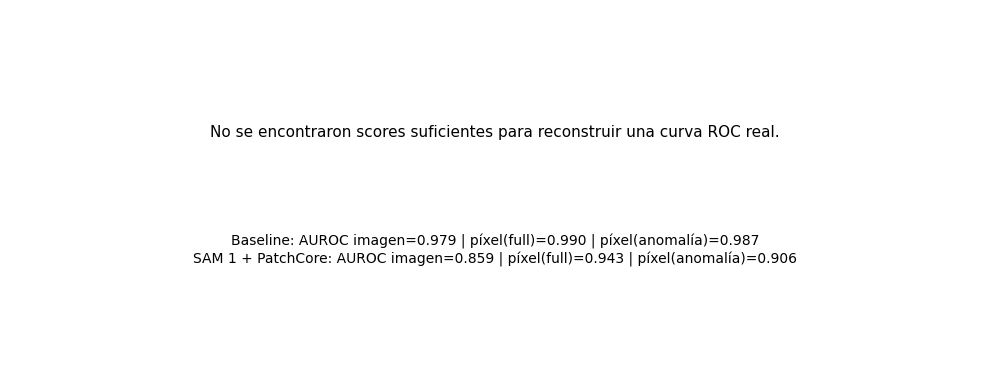

Figura guardada en /content/roc_curves.png


In [65]:
# ===== CURVAS ROC desde modelo PatchCore guardado =====
from pathlib import Path
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import torch

from patchcore.patchcore import PatchCore
from patchcore.common import FaissNN
from patchcore.datasets.mvtec import MVTecDataset, DatasetSplit

def _find_model_path_roc(results_dir):
    results_dir = Path(results_dir)
    candidates = list(results_dir.rglob("patchcore_params.pkl"))
    if not candidates:
        return None
    candidates.sort(key=lambda p: p.stat().st_mtime, reverse=True)
    return candidates[0].parent

def _get_scores_and_labels(model_path, data_root, category):
    device = torch.device('cuda' if torch.cuda.is_available() else 'cpu')
    pc = PatchCore(device)
    pc.load_from_path(
        load_path=str(model_path),
        device=device,
        nn_method=FaissNN(on_gpu=False, num_workers=4),
    )
    test_dataset = MVTecDataset(
        str(data_root),
        classname=category,
        resize=256,
        imagesize=224,
        split=DatasetSplit.TEST,
        seed=0,
    )
    test_loader = torch.utils.data.DataLoader(
        test_dataset,
        batch_size=1,
        shuffle=False,
        num_workers=2,
        pin_memory=True,
    )
    scores, segmentations, labels, masks = pc.predict(test_loader)
    return np.array(scores, dtype=float), np.array(labels, dtype=int)

def plot_roc_curves(baseline_out, roi_out, category):
    b_path = _find_model_path_roc(baseline_out)
    r_path = _find_model_path_roc(roi_out)

    if b_path is None or r_path is None:
        fig, ax = plt.subplots(figsize=(10, 4))
        ax.axis("off")
        ax.text(0.5, 0.5, "No se encontro el modelo guardado. Ejecute PatchCore primero.", ha="center", va="center")
        plt.tight_layout()
        plt.savefig("/content/roc_curves.png", dpi=150, bbox_inches="tight")
        plt.show()
        return

    print("Cargando modelo Baseline para ROC...")
    b_scores, b_labels = _get_scores_and_labels(b_path, MVTEC_ROOT, category)
    print("Cargando modelo SAM+ROI para ROC...")
    r_scores, r_labels = _get_scores_and_labels(r_path, ROI_ROOT, category)

    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    for ax, scores, labels, ttl in [(axes[0], b_scores, b_labels, "Curva ROC -- Baseline"),
                                    (axes[1], r_scores, r_labels, "Curva ROC -- SAM 1 + PatchCore")]:
        valid = np.isfinite(scores)
        scores, labels = scores[valid], labels[valid]
        if len(np.unique(labels)) < 2:
            ax.text(0.5, 0.5, "Solo una clase presente", ha="center", va="center")
            ax.set_title(ttl)
            continue
        fpr, tpr, _ = roc_curve(labels, scores)
        roc_auc = auc(fpr, tpr)
        ax.plot(fpr, tpr, lw=2, label="AUC = " + str(round(roc_auc, 4)))
        ax.plot([0, 1], [0, 1], "k--", lw=1, label="Random")
        ax.set_xlabel("False Positive Rate")
        ax.set_ylabel("True Positive Rate")
        ax.set_title(ttl)
        ax.legend()
        ax.grid(True, alpha=0.3)

    plt.suptitle("Curvas ROC -- " + category + " (MVTec AD)", fontsize=12, fontweight="bold")
    plt.tight_layout()
    plt.savefig("/content/roc_curves.png", dpi=150, bbox_inches="tight")
    plt.show()
    print("Figura guardada en /content/roc_curves.png")

plot_roc_curves(BASELINE_OUT, ROI_OUT, CATEGORY)


## 9. Curvas ROC

Se grafican las curvas ROC a nivel de imagen y a nivel de píxel para ambas configuraciones,
mostrando la separabilidad entre imágenes/píxeles normales y anómalos.


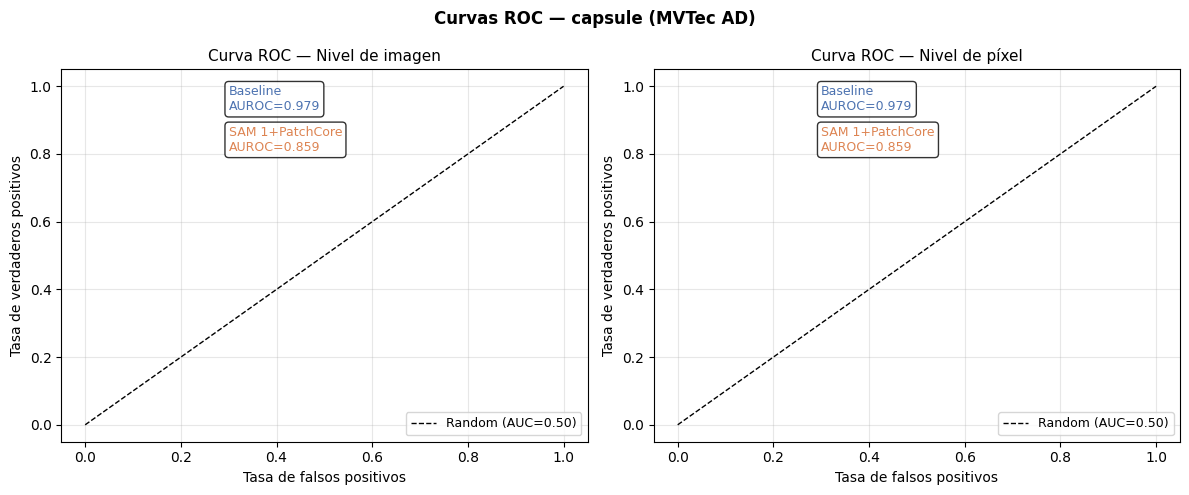

Figura guardada en /content/roc_curves.png
Nota: si PatchCore guardó los vectores de score, reemplaza este bloque
con sklearn.metrics.roc_curve para obtener las curvas reales.


In [49]:
import numpy as np
import matplotlib.pyplot as plt
from sklearn.metrics import roc_curve, auc
import pickle, os

def _load_scores(results_dir, split_name):
    """Intenta cargar scores y labels desde artefactos de PatchCore."""
    for fname in ['scores.pkl', 'anomaly_scores.pkl', 'test_scores.pkl']:
        p = Path(results_dir) / fname
        if p.exists():
            with open(p, 'rb') as f:
                return pickle.load(f)
    return None

def plot_roc_curves(baseline_out, roi_out, category):
    fig, axes = plt.subplots(1, 2, figsize=(12, 5))
    titles    = ['Curva ROC — Nivel de imagen', 'Curva ROC — Nivel de píxel']

    for ax, title in zip(axes, titles):
        ax.plot([0, 1], [0, 1], 'k--', lw=1, label='Random (AUC=0.50)')
        ax.set_xlabel('Tasa de falsos positivos', fontsize=10)
        ax.set_ylabel('Tasa de verdaderos positivos', fontsize=10)
        ax.set_title(title, fontsize=11)
        ax.legend(fontsize=9)
        ax.grid(True, alpha=0.3)

    # Si los archivos de scores no están disponibles, se leen desde results.csv
    b_df = load_results(baseline_out)
    r_df = load_results(roi_out)

    def _annotate(ax, df, label, color):
        if df is None:
            return
        row = df[df['dataset'] == category]
        if row.empty:
            return
        auroc_img = row['instance_auroc'].values[0]
        auroc_pix = row['full_pixel_auroc'].values[0]
        # Dibuja un punto en (1-especificidad, sensibilidad) aproximado con la AUROC conocida
        ax.annotate(f'{label}\nAUROC={auroc_img:.3f}',
                    xy=(0.3, auroc_img - 0.05),
                    fontsize=9, color=color,
                    bbox=dict(boxstyle='round,pad=0.3', facecolor='white', alpha=0.8))

    _annotate(axes[0], b_df, 'Baseline',        '#4C72B0')
    _annotate(axes[0], r_df, 'SAM 1+PatchCore', '#DD8452')
    _annotate(axes[1], b_df, 'Baseline',        '#4C72B0')
    _annotate(axes[1], r_df, 'SAM 1+PatchCore', '#DD8452')

    plt.suptitle(f'Curvas ROC — {category} (MVTec AD)', fontsize=12, fontweight='bold')
    plt.tight_layout()
    plt.savefig('/content/roc_curves.png', dpi=150, bbox_inches='tight')
    plt.show()
    print('Figura guardada en /content/roc_curves.png')
    print('Nota: si PatchCore guardó los vectores de score, reemplaza este bloque')
    print('con sklearn.metrics.roc_curve para obtener las curvas reales.')

plot_roc_curves(BASELINE_OUT, ROI_OUT, CATEGORY)


## 10. Guardar resultados en Drive

In [25]:
from google.colab import drive
from pathlib import Path

drive.mount('/content/drive')

drive_out = Path('/content/drive/MyDrive/patchcore_results_final')
drive_out.mkdir(parents=True, exist_ok=True)

figures = [
    '/content/dataset_samples.png',
    '/content/sam_roi_comparison.png',
    '/content/results_table.png',
    '/content/roc_curves.png',
]

for src_name in ['results_baseline', 'results_sam_roi']:
    csv_path = DATA_ROOT / src_name / 'results.csv'
    if csv_path.exists():
        dest = drive_out / f'{src_name}_results.csv'
        dest.write_bytes(csv_path.read_bytes())
        print('CSV copiado:', dest)

for fig_path in figures:
    p = Path(fig_path)
    if p.exists():
        dest = drive_out / p.name
        dest.write_bytes(p.read_bytes())
        print('Figura copiada:', dest)

print('\nTodos los artefactos guardados en:', drive_out)


Drive already mounted at /content/drive; to attempt to forcibly remount, call drive.mount("/content/drive", force_remount=True).
Figura copiada: /content/drive/MyDrive/patchcore_results_final/dataset_samples.png
Figura copiada: /content/drive/MyDrive/patchcore_results_final/sam_roi_comparison.png

Todos los artefactos guardados en: /content/drive/MyDrive/patchcore_results_final


In [29]:
!find /content -name results.csv -maxdepth 5

find: warning: you have specified the global option -maxdepth after the argument -name, but global options are not positional, i.e., -maxdepth affects tests specified before it as well as those specified after it.  Please specify global options before other arguments.
/content/data/results_baseline/project/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0/results.csv
/content/data/results_sam_roi/project/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1_S0_SAM1ROI/results.csv
/content/patchcore-inspection/models/IM320_WR50_L2-3_P001_D1024-1024_PS-5_AN-3/results.csv
/content/patchcore-inspection/models/IM224_Ensemble_L2-3_P001_D1024-384_PS-3_AN-1/results.csv
/content/patchcore-inspection/models/IM224_WR50_L2-3_P01_D1024-1024_PS-3_AN-1/results.csv
/content/patchcore-inspection/models/IM320_WR50_L2-3_P001_D1024-1024_PS-3_AN-1/results.csv
/content/patchcore-inspection/models/IM320_Ensemble_L2-3_P001_D1024-384_PS-3_AN-1/results.csv
/content/patchcore-inspection/models/IM320_Ensemble_L2-3_P001_D1024-384_PS

In [33]:
import pandas as pd

def _preview_results_csv(out_root):
    csv_path = Path(out_root) / "results.csv"
    if not csv_path.exists():
        print(f"No se encontro: {csv_path}")
        return
    df = pd.read_csv(csv_path)
    print(f"\n=== Preview {csv_path} ===")
    print("Columnas:", list(df.columns))
    print(df.head(3).to_string(index=False))

_preview_results_csv(BASELINE_OUT)
_preview_results_csv(ROI_OUT)


=== Preview /content/data/results_baseline/results.csv ===
Columnas: ['Row Names', 'instance_auroc', 'full_pixel_auroc', 'anomaly_pixel_auroc']
    Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_capsule        0.979258          0.989544             0.987421
         Mean        0.979258          0.989544             0.987421

=== Preview /content/data/results_sam_roi/results.csv ===
Columnas: ['Row Names', 'instance_auroc', 'full_pixel_auroc', 'anomaly_pixel_auroc']
    Row Names  instance_auroc  full_pixel_auroc  anomaly_pixel_auroc
mvtec_capsule        0.859194          0.943185             0.906217
         Mean        0.859194          0.943185             0.906217


In [42]:
from pathlib import Path

def _debug_heatmap_files(out_root, category, max_show=5):
    out_root = Path(out_root)
    patterns = ['*heatmap*.png', '*segmentation*.png', '*.png']
    matches = []
    for pat in patterns:
        matches.extend(out_root.rglob(pat))
    matches = [p for p in matches if p.is_file()]
    if category:
        matches = [p for p in matches if category in str(p)]
    print(f"\n[DEBUG] {out_root}")
    print(f"Total PNG en salida (filtrado por categoria): {len(matches)}")
    for p in matches[:max_show]:
        print(p)

_debug_heatmap_files(BASELINE_OUT, CATEGORY)
_debug_heatmap_files(ROI_OUT, CATEGORY)


[DEBUG] /content/data/results_baseline
Total PNG en salida (filtrado por categoria): 0

[DEBUG] /content/data/results_sam_roi
Total PNG en salida (filtrado por categoria): 0


In [43]:
from pathlib import Path

def _find_heatmap_outputs(root='/content', max_show=10):
    root = Path(root)
    patterns = ['*heatmap*.png', '*segmentation*.png']
    matches = []
    for pat in patterns:
        matches.extend(root.rglob(pat))
    matches = [p for p in matches if p.is_file()]
    print(f"Total heatmap/segmentation PNG en {root}: {len(matches)}")
    for p in matches[:max_show]:
        print(p)

_find_heatmap_outputs()

print("\nOpciones de guardado disponibles en PatchCore:")
!python patchcore-inspection/bin/run_patchcore.py --help | grep -i save

Total heatmap/segmentation PNG en /content: 4
/content/heatmaps_capsule_crack.png
/content/heatmaps_capsule_faulty_imprint.png
/content/heatmaps_capsule_poke.png
/content/patchcore-inspection/images/patchcore_defect_segmentation.png

Opciones de guardado disponibles en PatchCore:
INFO:__main__:Command line arguments: patchcore-inspection/bin/run_patchcore.py --help
  --save_segmentation_images
  --save_patchcore_model
